<a href="https://colab.research.google.com/github/julienessan/Gomycode_Cours_Data_Sciences/blob/main/Checkpoint_Personnaliser_classificateur_d%E2%80%99images.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Checkpoint: Personnaliser un classificateur d’images

**Objectif** :

Personnaliser un CNN pré-entraîné (par ex. VGG16, ResNet ou MobileNet) pour créer un classificateur d’images personnalisé en utilisant soit l’extraction de caractéristiques, soit l’affinage (fine-tuning).

## 1. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

keras.utils.set_random_seed(42)

## 2. Jeu de données : tf_flowers

3 670 photos de fleurs réparties en 5 classes : marguerite, pissenlit, rose, tournesol, tulipe. Le jeu ne contient qu'une partie `train`, donc je la découpe moi-même :
- **80 % pour l'entraînement** (environ 2 900 images) ;
- **20 % pour la validation** (environ 730 images).

In [3]:
!pip install -q importlib-resources

(ds_train, ds_val), info = tfds.load(
    "tf_flowers",
    split=["train[:80%]", "train[80%:]"],
    as_supervised=True,
    with_info=True,
)
noms = info.features["label"].names
NB_CLASSES = len(noms)

print("Classes :", noms)
print("Entraînement :", ds_train.cardinality().numpy(), "| Validation :", ds_val.cardinality().numpy())

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.HBRPOI_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
Classes : ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Entraînement : 2936 | Validation : 734


Quelques exemples :

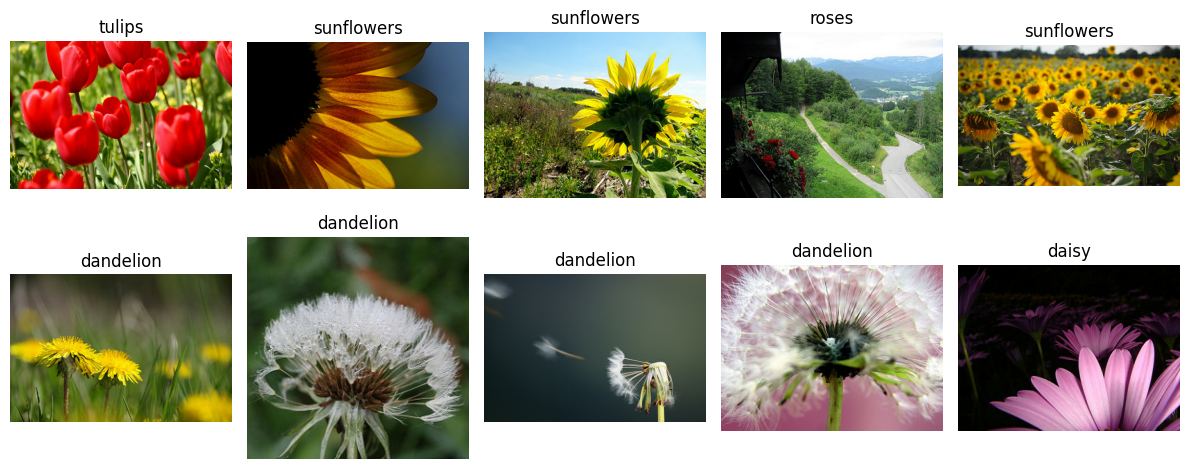

In [4]:
plt.figure(figsize=(12, 5))
for i, (image, label) in enumerate(ds_train.take(10)):
    plt.subplot(2, 5, i + 1)
    plt.imshow(image)
    plt.title(noms[label])
    plt.axis("off")
plt.tight_layout()
plt.show()

### Prétraitement

- **redimensionnement en 224×224**, la taille d'origine de VGG16 ;
- **`preprocess_input`** de VGG16 : les images doivent être préparées (canaux en BGR, moyenne d'ImageNet soustraite). On ne divise pas par 255.

In [5]:
TAILLE = 224
BATCH = 32

def preparer(image, label):
    image = tf.image.resize(image, (TAILLE, TAILLE))
    image = preprocess_input(image)
    return image, label

ds_train = ds_train.map(preparer).shuffle(1000).batch(BATCH).prefetch(tf.data.AUTOTUNE)
ds_val = ds_val.map(preparer).batch(BATCH).prefetch(tf.data.AUTOTUNE)

## 3. Charger VGG16 et choisir le fine-tuning

- `weights="imagenet"` : poids pré-entraînés sur ImageNet ;
- `include_top=False` : on supprime le classificateur d'origine (1 000 classes) et on garde les blocs convolutionnels.

**Mon choix : fine-tuning des N = 4 dernières couches.** Ce sont `block5_conv1`, `block5_conv2`, `block5_conv3` et `block5_pool`, c'est-à-dire tout le dernier bloc de VGG16. Les premières couches, qui détectent des bords, des couleurs et des textures, restent gelées.

In [6]:
base = VGG16(weights="imagenet", include_top=False, input_shape=(TAILLE, TAILLE, 3))

N = 4   # nombre de dernières couches à débloquer

for couche in base.layers[:-N]:
    couche.trainable = False
for couche in base.layers[-N:]:
    couche.trainable = True

print("Couches débloquées :", [c.name for c in base.layers if c.trainable])

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Couches débloquées : ['block5_conv1', 'block5_conv2', 'block5_conv3', 'block5_pool']


## 4. Nouvelle tête de classification

**GlobalAveragePooling2D → Dense → Dropout → Softmax**

In [8]:
entree = keras.Input(shape=(TAILLE, TAILLE, 3))
x = base(entree)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
sortie = layers.Dense(NB_CLASSES, activation="softmax")(x)

model = keras.Model(entree, sortie)

### Résumé de l'architecture

In [9]:
model.summary(expand_nested=True, show_trainable=True)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer_2 (InputLayer)  │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ vgg16 (Functional)          │ (None, 7, 7, 512)     │ 14,714,688 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ input_layer            │ (None, 224, 224, 3)   │          0 │   -   │
│ (InputLayer)                │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ block1_conv1 (Conv2D)  │ (None, 224, 224, 64)  │      1,792 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ block1_conv2 (Conv2D)  │ (None, 224, 224, 64)  │     36,928 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ block1_pool            │ (None, 112, 112, 64)  │          0 │   -   │
│ (MaxPooling2D)              │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ block2_conv1 (Conv2D)  │ (None, 112, 112, 128) │     73,856 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ block2_conv2 (Conv2D)  │ (None, 112, 112, 128) │    147,584 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ block2_pool            │ (None, 56, 56, 128)   │          0 │   -   │
│ (MaxPooling2D)              │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ block3_conv1 (Conv2D)  │ (None, 56, 56, 256)   │    295,168 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ block3_conv2 (Conv2D)  │ (None, 56, 56, 256)   │    590,080 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ block3_conv3 (Conv2D)  │ (None, 56, 56, 256)   │    590,080 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ block3_pool            │ (None, 28, 28, 256)   │          0 │   -   │
│ (MaxPooling2D)              │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ block4_conv1 (Conv2D)  │ (None, 28, 28, 512)   │  1,180,160 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ block4_conv2 (Conv2D)  │ (None, 28, 28, 512)   │  2,359,808 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ block4_conv3 (Conv2D)  │ (None, 28, 28, 512)   │  2,359,808 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ block4_pool            │ (None, 14, 14, 512)   │          0 │   -   │
│ (MaxPooling2D)              │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ block5_conv1 (Conv2D)  │ (None, 14, 14, 512)   │  2,359,808 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ block5_conv2 (Conv2D)  │ (None, 14, 14, 512)   │  2,359,808 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ block5_conv3 (Conv2D)  │ (None, 14, 14, 512)   │  2,359,808 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ block5_pool            │ (None, 7, 7, 512)     │          0 │   -   │
│ (MaxPooling2D)              │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d_1  │ (None, 512)           │          0 │   - 

 Total params: 14,847,301 (56.64 MB)

 Trainable params: 7,212,037 (27.51 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

## 5. Entraînement

In [10]:
EPOQUES = 15

model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-4),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

historique = model.fit(ds_train, validation_data=ds_val, epochs=EPOQUES)

Epoch 1/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 41s 310ms/step - accuracy: 0.5671 - loss: 1.2624 - val_accuracy: 0.8488 - val_loss: 0.4906
Epoch 2/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 19s 187ms/step - accuracy: 0.8144 - loss: 0.5497 - val_accuracy: 0.9060 - val_loss: 0.3230
Epoch 3/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 19s 190ms/step - accuracy: 0.8978 - loss: 0.3064 - val_accuracy: 0.9155 - val_loss: 0.2714
Epoch 4/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 197ms/step - accuracy: 0.9261 - loss: 0.2326 - val_accuracy: 0.9114 - val_loss: 0.2650
Epoch 5/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 197ms/step - accuracy: 0.9349 - loss: 0.2009 - val_accuracy: 0.9264 - val_loss: 0.2518
Epoch 6/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 19s 195ms/step - accuracy: 0.9564 - loss: 0.1304 - val_accuracy: 0.9373 - val_loss: 0.2584
Epoch 7/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 19s 195ms/step - accuracy: 0.9707 - loss: 0.0881 - val_accuracy: 0.9210 - val_loss: 0.2787
Epoch 8/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 21s 197ms/step - accuracy: 0.9779 - loss: 0.0738 - val_accu

## 6. Courbes de précision et de perte

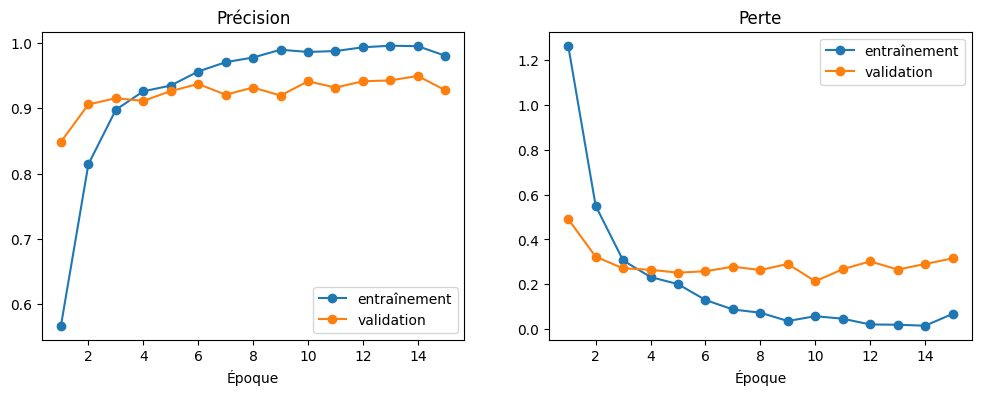

In [11]:
h = historique.history
ep = range(1, EPOQUES + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, h["accuracy"], "o-", label="entraînement")
ax[0].plot(ep, h["val_accuracy"], "o-", label="validation")
ax[0].set_title("Précision"); ax[0].set_xlabel("Époque"); ax[0].legend()

ax[1].plot(ep, h["loss"], "o-", label="entraînement")
ax[1].plot(ep, h["val_loss"], "o-", label="validation")
ax[1].set_title("Perte"); ax[1].set_xlabel("Époque"); ax[1].legend()
plt.show()

In [12]:
ep_min = int(np.argmin(h["val_loss"])) + 1

print(f"Précision train finale      : {h['accuracy'][-1]:.2%}")
print(f"Précision validation finale : {h['val_accuracy'][-1]:.2%}")
print(f"Meilleure précision val     : {max(h['val_accuracy']):.2%} (époque {int(np.argmax(h['val_accuracy'])) + 1})")
print(f"Écart train - val           : {(h['accuracy'][-1] - h['val_accuracy'][-1]) * 100:.1f} points")
print(f"val_loss minimale           : {min(h['val_loss']):.3f} à l'époque {ep_min}, finale : {h['val_loss'][-1]:.3f}")

Précision train finale      : 98.06%
Précision validation finale : 92.78%
Meilleure précision val     : 94.96% (époque 14)
Écart train - val           : 5.3 points
val_loss minimale           : 0.214 à l'époque 10, finale : 0.316


## 7. Réflexion

J’ai utilisé le fine-tuning : les 4 dernières couches de VGG16, soit tout le bloc 5, étaient débloquées dès le début, avec une nouvelle tête GlobalAveragePooling2D → Dense → Dropout → Softmax et un taux d’apprentissage faible (1e-4). Le modèle a très bien fonctionné sur tf_flowers : 84,8 % de précision en validation dès la première époque, puis un plateau entre 92 et 95 %, avec un meilleur score de 94,96 % à l’époque 14. À partir de l’époque 5 environ, j’observe un léger surapprentissage. La perte d’entraînement descend presque à zéro et la précision d’entraînement atteint 98 à 99 %, alors que la perte de validation, minimale à l’époque 10 (0,214), remonte jusqu’à 0,316 à la fin. Avec plus de temps, j’ajouterais de l’augmentation de données (retournement, rotation, zoom), qui convient bien aux fleurs, et un EarlyStopping pour garder les meilleurs poids au lieu de ceux de la dernière époque.